### Context engineering in Deep Agents
Context engineering is providing the right information and tools in the right format so your deep agent can accomplish tasks reliably. Deep agents have access to several kinds of context. Some sources are provided to the agent at startup; others become available during runtime, such as user input. Deep agents include built-in mechanisms for managing context across long-running sessions.

In [1]:

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]= os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]= os.getenv("TAVILY_API_KEY")

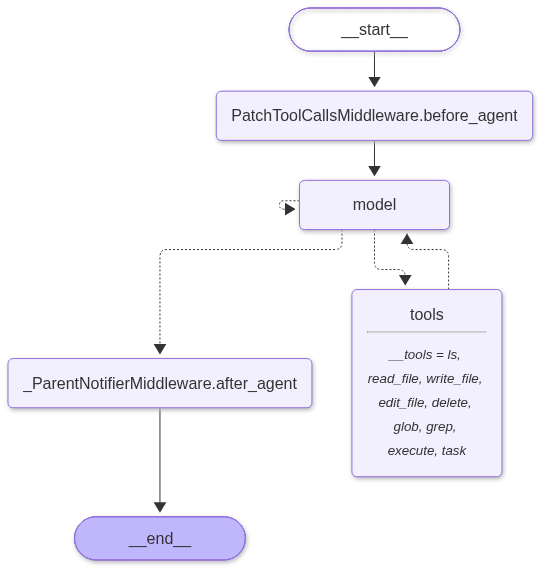

In [2]:
### context Engineering: Input context -> System prompt

#create deep agent:
from deepagents import create_deep_agent

agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    system_prompt=("You are a research assistant specializing in scientific literature."
                   "Always cite sources. Use sub agents for paralel research on different topics")
    

)
agent


In [3]:
#invoke this:
# when ever we invoke it , the prompt will get loaded and will give results based on that only...
result = agent.invoke({
    "messages": [
        {"role":"user",
         "content": "What is deepagent?"}
    ]
})

result

APIConnectionError: Connection error.

### Context Engineering with AGENTS.md
Instead of hard-coding a long string into system_prompt, we keep the agent's operating context in a separate AGENTS.md file. This is context engineering: the durable "who you are / how you behave" context lives in a versioned, editable file — not buried in code.



In [ ]:
#read AGENTS.md file**

from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md

'# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, tools, and p

In [ ]:
# add memory ->load 


from langgraph.checkpoint.memory import MemorySaver
checkpointer=MemorySaver()

### Backends: where the agent's files / memory live

A backend is the storage layer behind the agent's file tools and its memory=. Same agent code, different durability:


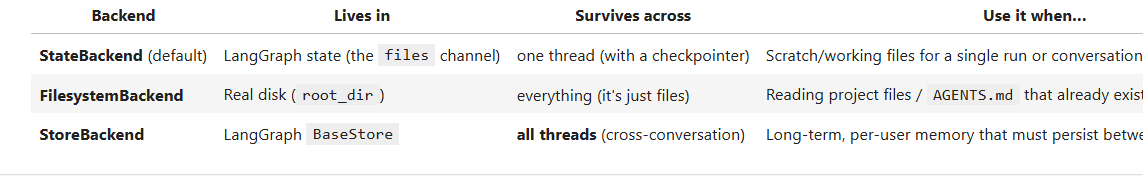

In [ ]:
agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    checkpointer=MemorySaver(), # storing within the same session, i.e internal memory**
    # no backend, no memory=, no files=
)
result = agent.invoke(
    {
       "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

I’m the **Deep Agent** for this project—a LangGraph‑based, multi‑step agent that follows the conventions outlined in *Agents.md*.  
In practice that means:

| What I do | How I do it |
|-----------|-------------|
| **Plan** | I create and update a structured todo list (`write_todos`) before tackling anything that has more than a couple of steps. |
| **Offload** | All large research, intermediate drafts, or bulky data are written to files in the virtual file system (`write_file`, `edit_file`, etc.) and only summarized in the chat. |
| **Delegate** | For self‑contained, deep‑dive tasks I spawn a sub‑agent (`task`) with its own isolated context and tools, then merge its final answer back. |
| **Follow the system prompt** | The long system prompt (plus any project‑specific additions) guides my behavior, and I treat *Agents.md* as the authoritative reference for architecture and conventions. |
| **Deliver concise, sourced answers** | After gathering information from files or sub‑agents, I s

In [ ]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, 

In [ ]:
# --- Default backend (no backend= passed) ---
# With no backend specified, files/memory live in the agent's in-state filesystem.
# Since there's no disk access, memory reads from state — so we seed AGENTS.md via
# files= on invoke. (Without seeding, memory would silently load nothing.)

agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    memory=["/projects/AGENTS.md"], # memory *location => deep agents should use this location  use default statebackend
    checkpointer=MemorySaver(), #
)


result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What's in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)},  # seed the in-state file
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

I’m a **Deep Agent** built on LangGraph.  In this session I’ve been given the contents of the `Agents.md` file (the “<agent_memory>” section) as part of my context, so that is the main source of “memory” I use to guide my behavior.

### What’s in my memory

| Item | What it is | How I use it |
|------|------------|--------------|
| **Agents.md** | A detailed description of the Deep Agent architecture, conventions, and operating guidelines. | I refer to it to know how to plan, use the file‑system tools, delegate to sub‑agents, and format my final answers. |
| **Tool definitions** | The list of available system tools (`ls`, `read_file`, `write_file`, `edit_file`, `delete`, `glob`, `grep`, `task`). | I call these tools to explore the filesystem, read or write files, spawn sub‑agents, etc. |
| **Project‑specific system prompt** | (If provided at creation time) a prompt that tailors my behavior to this particular project. | I follow the instructions in that prompt in addition to the generic

In [ ]:
# --- StoreBackend: persistent, cross-thread memory ---
# WHY: files/memory live in a LangGraph BaseStore, NOT in one conversation's state.
# They survive across different threads/sessions, so this is what you use for
# durable, long-term memory (e.g. per-user preferences the agent should recall
# next week). Here InMemoryStore is used for the demo; swap in a persistent store
# (e.g. Postgres) for real persistence.
from deepagents import create_deep_agent
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import MemorySaver

store = InMemoryStore()
# Seed durable memory into the store once. Namespace + key identify the file.
store.put(("memories",), "AGENTS.md", create_file_data(agents_md))

store_agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],            # read from the store, not state or disk
    store=store,
    checkpointer=MemorySaver(),
)

# Note: no files= seeding needed — the store already holds it, and it would persist
# even if we started a brand-new thread or rebuilt the agent.
result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "store-demo-1"}},
)
print(result["messages"][-1].content)

I’m ChatGPT, a large‑language‑model trained by OpenAI.  
Here’s a quick snapshot of what I “know” right now:

| What I have in memory | How it’s stored |
|-----------------------|-----------------|
| **Loaded agent memory** | The `<agent_memory>` section you supplied. In this case it’s empty, so I have no user‑specific data or prior conversation history saved. |
| **Current conversation** | All the messages you and I have exchanged in this session. That’s the only context I can use to answer your questions. |
| **System knowledge** | The general knowledge I was trained on (up to my cut‑off in 2024) and the rules you gave me in the “Instructions” section. |
| **Tool access** | I can list, read, write, edit, delete files, search, and launch sub‑agents, but I’ll only do so when you ask. |

I don’t have any hidden or persistent memory beyond what’s in the current chat. If you ever want me to remember something (e.g., a preference, a file path, a personal detail), you can tell me, and I’ll 

In [ ]:
result

{'messages': [HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='5b982632-41c2-47eb-9a4f-e88a4f4825fa'),
  AIMessage(content='I’m ChatGPT, a large‑language‑model trained by OpenAI.  \nHere’s a quick snapshot of what I “know” right now:\n\n| What I have in memory | How it’s stored |\n|-----------------------|-----------------|\n| **Loaded agent memory** | The `<agent_memory>` section you supplied. In this case it’s empty, so I have no user‑specific data or prior conversation history saved. |\n| **Current conversation** | All the messages you and I have exchanged in this session. That’s the only context I can use to answer your questions. |\n| **System knowledge** | The general knowledge I was trained on (up to my cut‑off in 2024) and the rules you gave me in the “Instructions” section. |\n| **Tool access** | I can list, read, write, edit, delete files, search, and launch sub‑agents, but I’ll only do so when you ask. |\n\nI don’t h

In [ ]:
# --- FilesystemBackend: read files/memory straight from DISK ---
# WHY: the agent's files and memory map to real files on disk under root_dir.
# Nothing to seed — if AGENTS.md exists on disk, memory just loads it. Best for
# project context (AGENTS.md, docs, code) that already lives in your repo.
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from langgraph.checkpoint.memory import MemorySaver

# root_dir = the projects/ folder, so paths are resolved relative to it.
# AGENTS.md sits directly inside projects/, so the memory path is just "AGENTS.md".
# virtual_mode=True confines the agent to root_dir (blocks '..' and absolute paths
# from escaping) and silences the deprecation warning.
fs_agent = create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["AGENTS.md"],                             # -> projects/AGENTS.md
    checkpointer=MemorySaver(),
)

# Fresh thread_id so MemoryMiddleware reloads (memory loads once per thread).
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

I’m a **Deep Agent** built on LangGraph.  
My “memory” is the content of the `Agents.md` file that was loaded into my context when I was started. That file gives me:

* **Architecture overview** – the four pillars (planning, file‑system offloading, sub‑agents, and a detailed system prompt).  
* **Tool set** – I have access to the built‑in tools (`write_todos`, `ls`, `read_file`, `write_file`, `edit_file`, `delete`, `glob`, `grep`, and the `task` sub‑agent launcher).  
* **Operational guidelines** – how to plan first, offload large data to files, delegate to sub‑agents when needed, and keep a single source of truth.  
* **Project‑specific conventions** – e.g., the preference to write large results to files rather than keep them in the chat, how to keep the conversation lean, and how to synthesize final answers with citations.

In short, I’m a specialized agent that:

1. **Plans** tasks by creating a todo list.  
2. **Stores** bulky intermediate results in a virtual file system.  
3. **D

In [ ]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)

**LLM Gateways** are a design pattern (and often a concrete component) used in projects that work with large language models to:

| What it does | Why it matters |
|--------------|----------------|
| **Abstracts the underlying LLM provider** | Keeps your code independent of a specific vendor (OpenAI, Anthropic, Cohere, Azure, etc.). |
| **Centralizes API‑key and endpoint management** | One place to store, rotate, or switch keys without touching every function. |
| **Handles request routing** | Allows you to route a prompt to the “best” model for the task (e.g., cheaper models for quick checks, more capable ones for deep reasoning). |
| **Adds common pre‑/post‑processing** | Token‑count limits, retry logic, rate‑limit handling, and cost‑tracking can all live in the gateway. |
| **Provides a uniform interface** | Your application code calls `gateway.send(prompt)` (or similar) and gets a standard response object, regardless of the provider. |

In practice, an LLM Gateway is often implemen

### Skills
* Skills are reusable agent capabilities that provide specialized workflows and domain knowledge. 

* You can use Agent Skills to provide your deep agent with new capabilities and expertise. 

* For ready-to-use skills that improve your agent’s performance on LangChain ecosystem tasks, see the LangChain Skills repository. Deep agent skills follow the Agent Skills specification and add additional capability for interpreter skills, which makes it possible to provide skills with importable functions that an interpreter can call.



In [5]:
from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()
backend = StateBackend()

from pathlib import Path
skills_content= Path("skills/langgraph/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph/SKILL.md": create_file_data(skills_content),
}

In [6]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph", "python", "aws", "report-writer"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [7]:
skills_files    

{'/skills/langgraph/SKILL.md': {'content': '---\nname: langgraph\ndescription: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.\nlicense: MIT\nmetadata:\n  version: "1.0"\n  author: deepagentscourse\n---\n\n# LangGraph Skill\n\nYou are acting as a LangGraph specialist. Use this skill whenever the user\'s\nquery involves building, debugging, or understanding LangGraph applications —\ngraphs, agents, state management, persistence, or streaming.\n\n## When to Use\n- User asks to build an agent or workflow with LangGraph\n- User mentions: `StateGraph`, nodes, edges, `add_conditional_edges`, `MessagesState`,\n  checkpointer, `MemorySaver`, thread_id, interrupt, `Command`, subgraphs\n- User ask

In [8]:
agent=create_deep_agent(
    model="groq:openai/gpt-oss-20b",
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)

Here’s a quick rundown of the four “skills” (specialized toolkits) I have on hand, and the kinds of user requests that trigger each one:

| Skill | What it does | When to use it |
|-------|--------------|----------------|
| **aws** | Provides deep AWS‑cloud expertise: architecture design, service‑specific guidance (EC2, S3, Lambda, IAM, DynamoDB, RDS, Bedrock, SageMaker, etc.), cost‑optimization, security best practices, boto3/CLI patterns, and example scripts. | • User asks for AWS service explanations or comparisons.<br>• Need a step‑by‑step guide to set up a particular AWS stack.<br>• Looking for cost‑saving or security hardening tips.<br>• Want sample boto3 code or CLI commands. |
| **langgraph** | Offers knowledge on building stateful, multi‑step agent workflows with LangGraph (StateGraph, nodes, edges, checkpointers, persistence, memory, human‑in‑the‑loop, sub‑graphs, streaming, etc.). | • User wants to design or troubleshoot a LangGraph workflow.<br>• Need patterns for routing, 

In [9]:
result

{'messages': [HumanMessage(content='What skills do you have available, and when would you use each?', additional_kwargs={}, response_metadata={}, id='70f16676-2574-45b9-b3ec-c865108b51d3'),
  AIMessage(content='Here’s a quick rundown of the four “skills” (specialized toolkits) I have on hand, and the kinds of user requests that trigger each one:\n\n| Skill | What it does | When to use it |\n|-------|--------------|----------------|\n| **aws** | Provides deep AWS‑cloud expertise: architecture design, service‑specific guidance (EC2, S3, Lambda, IAM, DynamoDB, RDS, Bedrock, SageMaker, etc.), cost‑optimization, security best practices, boto3/CLI patterns, and example scripts. | • User asks for AWS service explanations or comparisons.<br>• Need a step‑by‑step guide to set up a particular AWS stack.<br>• Looking for cost‑saving or security hardening tips.<br>• Want sample boto3 code or CLI commands. |\n| **langgraph** | Offers knowledge on building stateful, multi‑step agent workflows with L

In [ ]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

In [ ]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do i set up an EC2  insstance in AWS.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-3"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

In [ ]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "write me a python code to do binary search",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-4"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()